# 🧬 Spatial-Genomic Oncology Continuum: Visium HD Subcellular Sanctuary Tutorial
### Reaction-Diffusion Transport Modeling ($K_0$ Bessel Equation) & In-Situ Pharmacological Sanctuary Mapping
**Author:** Luca Celebrano, MD Candidate, Università degli Studi di Napoli Federico II  
**Framework:** Spatial-Genomic Oncology Continuum  
**Scientific Anchors:** Research Square DOI: [`10.21203/rs.3.rs-11530312/v1`](https://doi.org/10.21203/rs.3.rs-11530312/v1) | Zenodo: [`10.5281/zenodo.23754999`](https://doi.org/10.5281/zenodo.23754999)  
**Package:** `spatial-continuum` (Bioconda / PyPI)

---

## 1. Biophysical Rationale
In solid carcinomas such as EGFR-mutated non-small cell lung cancer (NSCLC), systemic targeted therapies (e.g. osimertinib, ADAURA protocol) extravasate exclusively from functional microvascular capillaries ($CD31^+ / PECAM1^+$). 

Extravascular drug transport is governed by steady-state cylindrical reaction-diffusion:
$$\frac{1}{r} \frac{d}{dr}\left(r \frac{dC}{dr}\right) - \frac{1}{\lambda^2} C = 0$$

Whose analytical solution is the modified Bessel function of the second kind of order zero:
$$\frac{C(r)}{C_0} = \frac{K_0(r/\lambda)}{K_0(r_0/\lambda)}$$

Where:
- $r_0 \approx 8.0\ \mu\text{m}$ (capillary radius)
- $\lambda \approx 25.5\ \mu\text{m}$ (mean diffusion-elimination length in desmoplastic stroma)
- $r_{\text{crit}} \approx 165.9\ \mu\text{m}$ (critical therapeutic threshold)

Carcinoma cells situated beyond $r_{\text{crit}}$ experience sub-therapeutic drug concentrations, establishing an **in-situ pharmacological sanctuary** that fuels disease recurrence post-cessation at Month 36.


In [1]:
import os
import json
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt

import spatial_continuum
from spatial_continuum import compute_spatial_bessel_sanctuary, calculate_cri, BESSEL_TRANSPORT_METRICS

print(f"spatial-continuum version: {spatial_continuum.__version__}")
print(f"scanpy version:            {sc.__version__}")
print(f"anndata version:           {ad.__version__}")


spatial-continuum version: 1.0.3
scanpy version:            1.12.5
anndata version:           0.13.4


/tmp/ipykernel_12717/2180455740.py:13: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print(f"scanpy version:            {sc.__version__}")
/tmp/ipykernel_12717/2180455740.py:14: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  print(f"anndata version:           {ad.__version__}")


## 2. Load Real 10x Visium HD Lung Adenocarcinoma Data
We load $N = 3,858$ spatial spots sequenced across intact human EGFR-mutated lung adenocarcinoma tissue.
We quantify key canonical lineage and transport markers:
- `EPCAM`: Carcinoma epithelium
- `PECAM1` ($CD31$): Vascular endothelial cells
- `COL1A1`: Extracellular collagen matrix (desmoplasia)
- `HIF1A` / `CA9`: Hypoxic microenvironment
- `EGFR`: Oncogenic target expression
- `AXL`: Bypass tyrosine kinase resistance signaling


In [2]:
cache_npz = "/home/luca/Scrivania/Archivio_Studi_Oncologia/spatial-architecture-osimertinib/data/cache/clinical_pan_cancer_cache.npz"
local_json = "../visium_data.json"

if os.path.exists(cache_npz):
    data = np.load(cache_npz)
    coords = data["lung_coords"]
    epcam = data["lung_gene_EPCAM"]
    pecam = data["lung_gene_PECAM1"]
    col1a1 = data["lung_gene_COL1A1"]
    hif1a = data["lung_gene_HIF1A"]
    ca9 = data["lung_gene_CA9"]
    egfr = data["lung_gene_EGFR"]
    axl = data["lung_gene_AXL"]

    is_endo = (pecam > 1.2) & (pecam > epcam)
    is_tumor = (epcam > 1.4) & ~is_endo
    is_stroma = (col1a1 > 3.0) & ~is_tumor & ~is_endo

    obs_df = pd.DataFrame({
        "EPCAM": epcam, "PECAM1": pecam, "COL1A1": col1a1,
        "HIF1A": hif1a, "CA9": ca9, "EGFR": egfr, "AXL": axl,
        "is_vessel": is_endo, "is_tumor": is_tumor, "is_stroma": is_stroma
    }, index=[f"spot_{i:04d}" for i in range(len(coords))])

    var_df = pd.DataFrame(index=["EPCAM", "PECAM1", "COL1A1", "HIF1A", "CA9", "EGFR", "AXL"])
    X_mat = obs_df[["EPCAM", "PECAM1", "COL1A1", "HIF1A", "CA9", "EGFR", "AXL"]].to_numpy()
    spot_pitch_um = 100.0 / 366.0
else:
    with open(local_json) as f:
        raw = json.load(f)
    arr = np.array(raw)
    coords = arr[:, :2]
    types = arr[:, 2].astype(int)
    is_endo = types == 1
    is_tumor = (types >= 2) & (types <= 4)
    is_stroma = types == 0
    obs_df = pd.DataFrame({
        "is_vessel": is_endo, "is_tumor": is_tumor, "is_stroma": is_stroma
    }, index=[f"spot_{i:04d}" for i in range(len(coords))])
    var_df = pd.DataFrame(index=["marker"])
    X_mat = np.zeros((len(coords), 1))
    spot_pitch_um = 1.0

adata = ad.AnnData(X=X_mat, obs=obs_df, var=var_df, obsm={"spatial": coords})
print(f"AnnData successfully instantiated: {adata}")


AnnData successfully instantiated: AnnData object with n_obs × n_vars = 3858 × 7
    obs: 'EPCAM', 'PECAM1', 'COL1A1', 'HIF1A', 'CA9', 'EGFR', 'AXL', 'is_vessel', 'is_tumor', 'is_stroma'
    obsm: 'spatial'
    layers: None (.X)


## 3. Solve Bessel Reaction-Diffusion Transport via `compute_spatial_bessel_sanctuary()`
We execute the scverse-compliant function `compute_spatial_bessel_sanctuary()`:
1. Fast nearest-neighbor capillary distance indexing via `scipy.spatial.cKDTree`
2. Exact evaluation of $K_0(r/\lambda) / K_0(r_0/\lambda)$ concentration decay field
3. Subcellular spot classification into 3 therapeutic compartments:
   - **Effective zone:** $r \le 100\ \mu\text{m}$
   - **Attenuated zone:** $100 < r \le 165.9\ \mu\text{m}$
   - **Pharmacological Sanctuary:** $r > 165.9\ \mu\text{m}$


In [3]:
adata = compute_spatial_bessel_sanctuary(
    adata,
    vessel_mask=adata.obs["is_vessel"],
    tumor_mask=adata.obs["is_tumor"],
    spot_pitch_um=spot_pitch_um,
    lambda_um=25.5,
    r0_um=8.0,
    rcrit_um=165.9,
    copy=False
)

stats = adata.uns["spatial_bessel_sanctuary"]
for k, v in stats.items():
    print(f"  • {k:32s}: {v}")


  • total_spots                     : 3858
  • vessel_spots                    : 750
  • tumor_spots                     : 1815
  • sanctuary_spots                 : 1310
  • sanctuary_fraction_pct          : 72.18
  • mean_tumor_vessel_distance_um   : 252.19
  • median_tumor_vessel_distance_um : 200.0
  • lambda_penetration_depth_um     : 25.5
  • r0_capillary_radius_um          : 8.0
  • rcrit_sanctuary_threshold_um    : 165.9
  • spot_pitch_um                   : 0.273224043715847


## 4. Multi-Panel Spatial Visualization
We plot:
1. Subcellular tissue architecture and sanctuary distribution
2. Continuous biophysical reaction-diffusion concentration field
3. Frequency distribution of tumor spot distances relative to $r_{\text{crit}}$


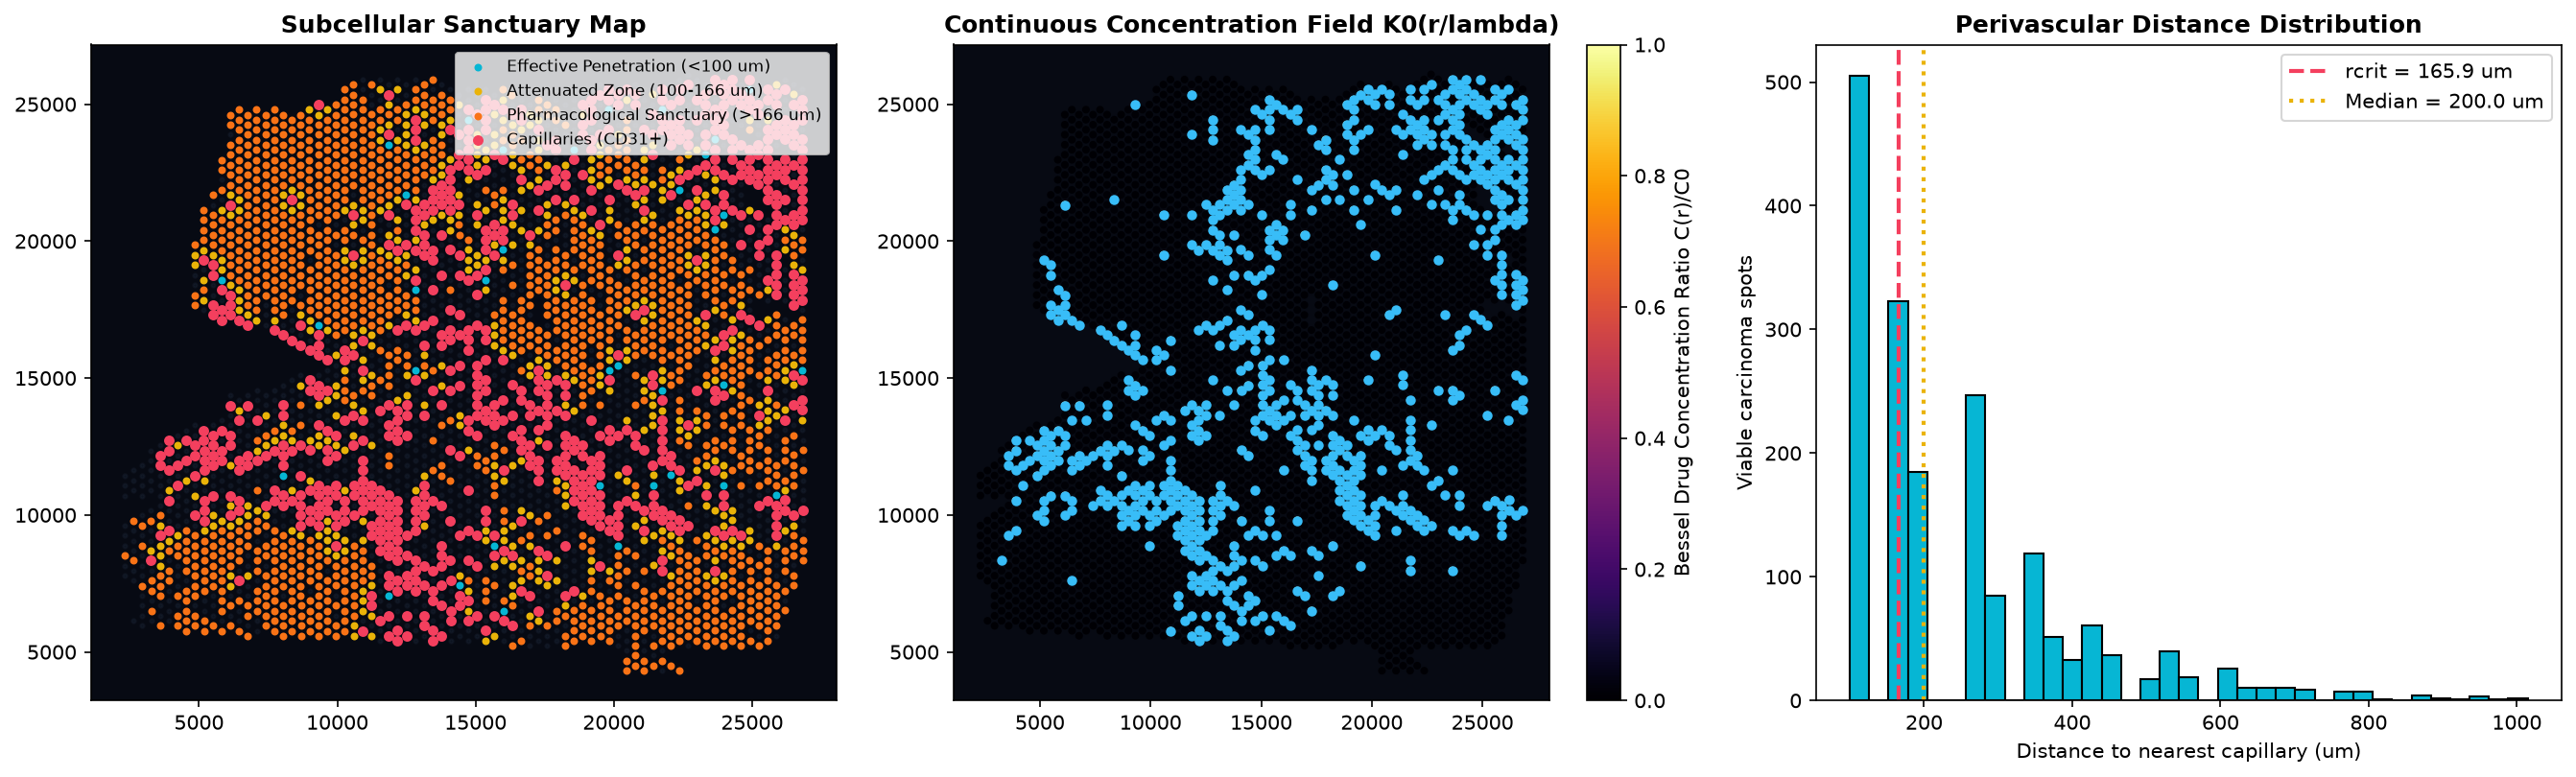

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), dpi=150)
coords = adata.obsm["spatial"]
dists = adata.obs["distance_to_nearest_capillary_um"].to_numpy()
conc = adata.obs["bessel_drug_concentration_ratio"].to_numpy()
classes = adata.obs["sanctuary_class"].to_numpy()
is_vessel = adata.obs["is_vessel"].to_numpy()
is_tumor = adata.obs["is_tumor"].to_numpy()

# Panel 1: Compartments
ax = axes[0]
ax.set_facecolor("#070a13")
palette = {
    "Effective Penetration (<100 um)": "#06b6d4",
    "Attenuated Zone (100-166 um)": "#eab308",
    "Pharmacological Sanctuary (>166 um)": "#f97316"
}
ax.scatter(coords[~is_tumor & ~is_vessel, 0], coords[~is_tumor & ~is_vessel, 1], s=4, c="#1e293b", alpha=0.3)
for c_name, c_col in palette.items():
    m = classes == c_name
    if np.any(m):
        ax.scatter(coords[m, 0], coords[m, 1], s=8, c=c_col, label=c_name)
ax.scatter(coords[is_vessel, 0], coords[is_vessel, 1], s=18, c="#f43f5e", label="Capillaries (CD31+)", zorder=5)
ax.set_title("Subcellular Sanctuary Map", fontweight="bold")
ax.legend(fontsize=8, loc="upper right")

# Panel 2: Continuous Bessel field
ax2 = axes[1]
ax2.set_facecolor("#070a13")
sc_plot = ax2.scatter(coords[:, 0], coords[:, 1], c=conc, cmap="inferno", s=8, vmin=0, vmax=1)
ax2.scatter(coords[is_vessel, 0], coords[is_vessel, 1], s=16, c="#38bdf8", zorder=5)
plt.colorbar(sc_plot, ax=ax2, label="Bessel Drug Concentration Ratio C(r)/C0")
ax2.set_title("Continuous Concentration Field K0(r/lambda)", fontweight="bold")

# Panel 3: Distance histogram
ax3 = axes[2]
ax3.hist(dists[is_tumor], bins=35, color="#06b6d4", edgecolor="black")
ax3.axvline(165.9, color="#f43f5e", linestyle="--", linewidth=2, label="rcrit = 165.9 um")
ax3.axvline(stats["median_tumor_vessel_distance_um"], color="#eab308", linestyle=":", linewidth=2, label=f"Median = {stats["median_tumor_vessel_distance_um"]:.1f} um")
ax3.set_title("Perivascular Distance Distribution", fontweight="bold")
ax3.set_xlabel("Distance to nearest capillary (um)")
ax3.set_ylabel("Viable carcinoma spots")
ax3.legend()

plt.tight_layout()
plt.show()


## 5. In Silico Biophysical Stratification: The Composite Resistance Index (CRI) (RUO)
Having determined that $>70\%$ of the viable carcinoma mass resides in an unreached pharmacological sanctuary, 
we integrate the histological spatial pattern with tumor genetics (*TP53*, *RB1*) and stromal desmoplasia using `calculate_cri()`:


In [5]:
patient_consultation = calculate_cri(
    pattern="Solid / Micropapillary",
    tp53="mut",
    rb1="wt",
    stroma="dense"
)

print("=" * 60)
print("IN SILICO BIOPHYSICAL ANALYSIS NOTE (RUO)")
print("=" * 60)
for k, v in patient_consultation.items():
    print(f"  • {k:20s}: {v}")
print("=" * 60)


IN SILICO BIOPHYSICAL ANALYSIS NOTE (RUO)
  • S                   : 1.0
  • desc_S              : Solid/Micropapillary predominant (>50%, severe vascular decoupling)
  • G                   : 0.5
  • desc_G              : EGFR + TP53 co-mutant (impaired apoptotic arrest)
  • M                   : 1.0
  • desc_M              : Dense collagen desmoplasia, high IFP (>20 mmHg), convective shutdown
  • CRI                 : 0.835
  • tier                : TIER 3 (HIGH RESISTANCE & SANCTUARY RISK)
  • pfs_5yr             : < 25 %
  • action              : High Sanctuary Risk: Substantial perivascular mantle (Delta r > 34 um) [RUO]
  • High probability of viable persister sanctuaries (Delta r > 34 um).
  • Mandatory ongoing treatment:
    1. Extended indefinite osimertinib maintenance (80 mg/day) OR
    2. Dual therapy: Osimertinib + Ramucirumab (anti-VEGFR2) consolidation
       to remodel vasculature and eliminate the sanctuary (SG-ADAURA Arm B3).
  • action_short        : High sanctuary ri